<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/Pra%CC%81cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

* Nombre: Jorge Alberto Caraveo Balderas
* Matricula: 274702

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*  1.1 Convierte si es necesario la variable location a tipo de dato categórico
*  1.2 Usa la instrucción describe() en las variables salary y cost
* 1.3 Cuenta la cantidad de datos que hay por categoría en location
* 1.4 Convierte la variable location usando one-hot encoding



In [37]:
#Cargar las librerias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [44]:
# 1. Cargar el conjunto de datos y seleccionar las columnas indicadas
ruta_archivo = '/content/college.csv'
df = pd.read_csv(ruta_archivo)[['salary', 'cost', 'location']]
print(df.dtypes)

# 1.1 Convierte la variable location a tipo de dato categórico (Se convierte debido a que es una columna tipo "Object")
df['location'] = df['location'].astype('category')
print("Tipo de datos")
print(df.dtypes)
print()

# 1.2 Usa la instrucción describe() en las variables salary y cost
print("Estadísticas descriptivas de 'salary' y 'cost")
print(df[['salary', 'cost']].describe())
print()

# 1.3 Contar la cantidad de datos por categoría en 'location'
print("Conteo de datos por categoría en 'location'")
print(df['location'].value_counts())
print()

# 1.4 Convertir la variable 'location' usando one-hot encoding (con K-1 variables dummy para regresión)
df_encoded = pd.get_dummies(df, columns=['location'], drop_first=True, dtype=int)
print("Primeras filas con One-Hot Encoding (K-1)")
print(df_encoded.head())

salary       int64
cost         int64
location    object
dtype: object
Tipo de datos
salary         int64
cost           int64
location    category
dtype: object

Estadísticas descriptivas de 'salary' y 'cost
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000

Conteo de datos por categoría en 'location'
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64

Primeras filas con One-Hot Encoding (K-1)
   salary    cost  location_NE  location_S  location_W
0  119000  189300            1           0           0
1  121000  189600            1           0           0
2  123000  188400            1           0           0
3  123000  188700            1           0           0
4  110000  194200            1   

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   2.1 Crea un histograma de la columna salary. Discute lo que observas
* 2.2 Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* 2.3 Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




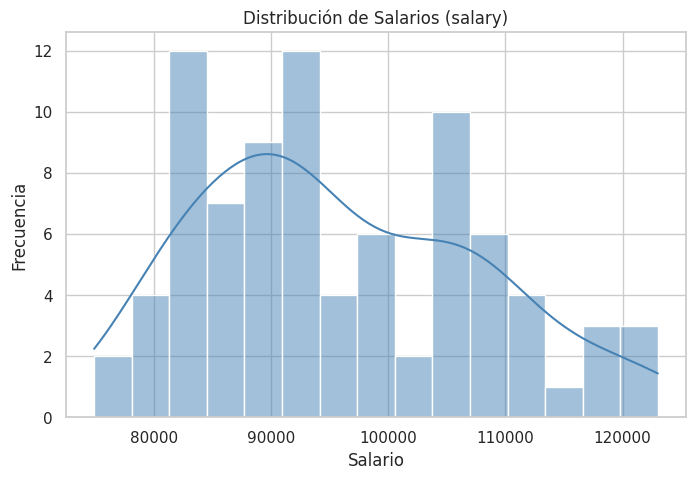

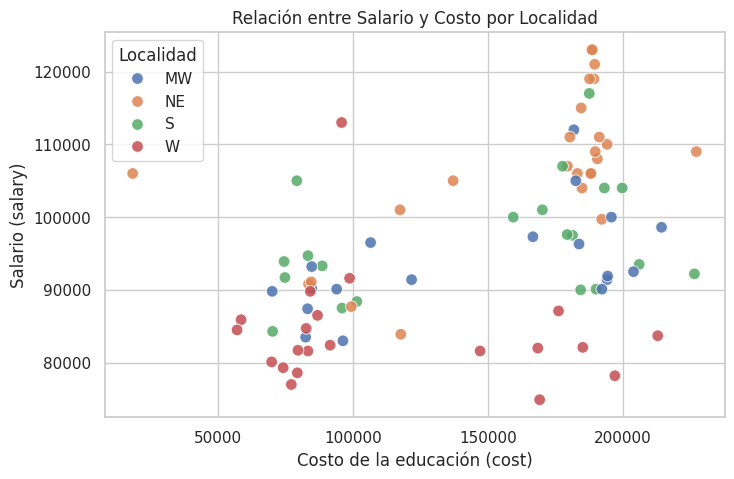

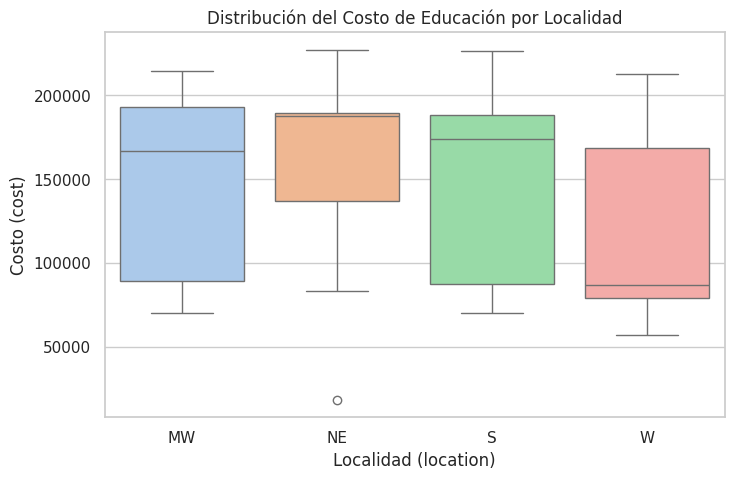

In [39]:

# Crea un histograma de la columna salary.
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='salary', kde=True, bins=15, color='steelblue')
plt.title('Distribución de Salarios (salary)')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.show()

#Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la
# educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='deep', s=70, alpha=0.85)
plt.title('Relación entre Salario y Costo por Localidad')
plt.xlabel('Costo de la educación (cost)')
plt.ylabel('Salario (salary)')
plt.legend(title='Localidad')
plt.show()

# Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad.
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='location', y='cost', hue='location', palette='pastel', legend=False)
plt.title('Distribución del Costo de Educación por Localidad')
plt.xlabel('Localidad (location)')
plt.ylabel('Costo (cost)')
plt.show()

### Conclusiones del Análisis Exploratorio de los Datos (AED)

* **2.1 Histograma de `salary`:**
  La distribución de los salarios abarca aproximadamente desde los 80,000 hasta los 120,000, mostrando una ligera asimetría hacia la derecha y un comportamiento ligeramente bimodal. La mayor concentración de datos se ubica entre los 80,000 y 5,000,, mientras que los salarios superiores a 115,000 son los menos frecuentes

* **2.2 Diagrama de dispersión de `salary` vs `cost` por `location`:**
  Se aprecia una relación positiva entre el costo educativo y el salario (a mayor costo, suele observarse un mayor salario), pero los datos se agrupan en dos bloques principales de costo y el comportamiento varía claramente según la localidad
  * **NE (naranja):** Concentra los salarios más altos en el rango de costos elevados (superando los 105,000 y llegando a más de 120,000)
  * **W (rojo):** Presenta mayoritariamente los salarios más bajos (entre 75,000 y 90,000), incluso cuando el costo de educación supera los 160,000
  * **MW (azul) y S (verde):** Se mantienen en niveles salariales intermedios (entre 85,000 y 105,000)

* **2.3 Boxplot de `cost` por `location`:**
  Existen diferencias claras en la distribución de los costos educativos según la ubicación:
  * **NE:** Tiene la mediana de costo más alta (Muy próxima al tercer cuartil, lo que indica que más de la mitad de sus instituciones tienen costos elevados) y presenta un valor atípico inferior por debajo de los 25,000.
  * **S y MW:** Muestran medianas altas pero con una dispersión mucho más amplia
  * **W:** Registra la mediana más baja de todas las localidades, indicando que más de la mitad de sus observaciones se concentran en costos bajos, aunque el tercer cuartil se extiende hasta arriba de 150,000

  **Conclusion general:**
  - El análisis exploratorio confirma que el costo de la educación influye positivamente en el salario, pero no explica la variabilidad por sí solo. La variable categórica location introduce desplazamientos notables en los niveles de ingreso. Por lo tanto, la regresión lineal múltiple resulta indispensable para capturar estos efectos fijos regionales y evitar el sesgo por omisión de variables

# 3. Construcción del modelo de regresión

- 3.1 Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- 3.2 Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [40]:

# Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
X = df_encoded.drop(columns=['salary'])
y = df_encoded['salary']
modelo = LinearRegression()
modelo.fit(X, y)

#  Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada)
print(f"Intercepto (B0): {modelo.intercept_:.4f}\n")

coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_
})
print("Coeficientes del Modelo")
print(coeficientes.to_string(index=False))

Intercepto (B0): 84988.7162

Coeficientes del Modelo
   Variable  Coeficiente
       cost     0.060518
location_NE 12032.819692
 location_S  2800.345026
 location_W -7721.420103


### 3 Interpretación de Resultados y Conclusiones del Modelo

#### 1. **¿Qué nos indican los números del modelo?**

* **Punto de partida (Intercepto = 84,988):** Representa el sueldo base estimado para un egresado de la región del MW, que sirve como nuestro grupo base de comparación (Debido a que pandas toma por defecto, el primero por orden alfabético)
* **Impacto del costo educativo (0.0605):** El costo de la carrera sí suma, pero de forma moderada. Por cada 100 dólares adicionales invertidos en colegiatura, el salario anual aumenta en promedio solo 6.05 dólares, siempre que comparemos dentro de la misma región
* **Region NE (+12,033):** Estudiar en el (NE) otorga la mayor ventaja salarial del país. Con el mismo costo de carrera, ganan 12,032 dólares más al año frente al MW.
* **Region S (+2,800):** Los egresados del (S) obtienen un incremento moderado de 2,800 dólares anuales respecto a la base del MW
* **Region W (-7,721):** El (W) presenta el peor escenario de retorno salarial. A igualdad de costo, sus egresados ganan 7,721 dólares menos al año que los del MW

#### 2. **Caso práctico: Misma inversión, sueldos distintos

Si cuatro estudiantes pagan exactamente una colegiatura de 100,000 dólares, el modelo proyecta los siguientes ingresos anuales según la zona:

* **(NE):** 103,073 dólares
* **(S):** 93,841 dólares
* **(MW):** 91,041 dólares
* **(W):** 83,319 dólares

Nota: Formula utilizada (100,000 USD * Costo) + (Region)

#### Conclusión definitiva del estudio

1. **La ubicación pesa mucho más que la colegiatura:** La brecha salarial entre estudiar en el Noreste y en el Oeste con la misma inversión educativa supera los 19,750 dólares anuales
2. **Valor del modelo multivariable:** Incorporar la ubicación geográfica resolvió las anomalías detectadas en el análisis exploratorio. Un modelo que solo considere el costo no sirve para predecir la realidad del mercado laboral, ya que la economía regional puede influir

# 4. Análisis de Residuos

- 4.1 Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- 4.2 Crea una gráfica de los errores residuales. Discute lo que observas

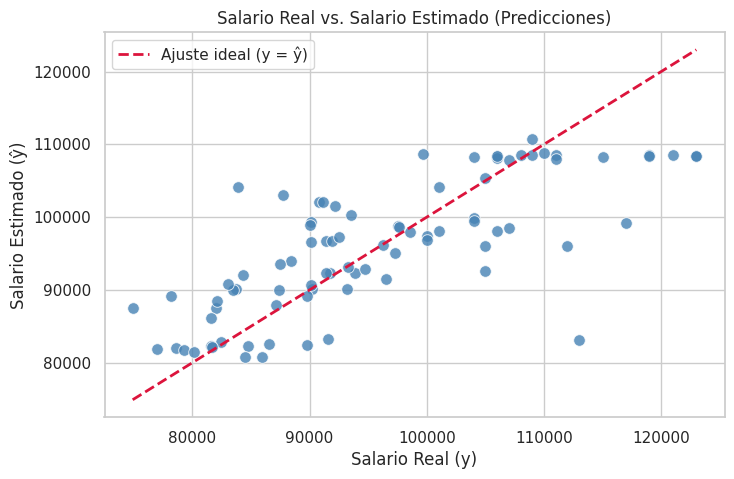

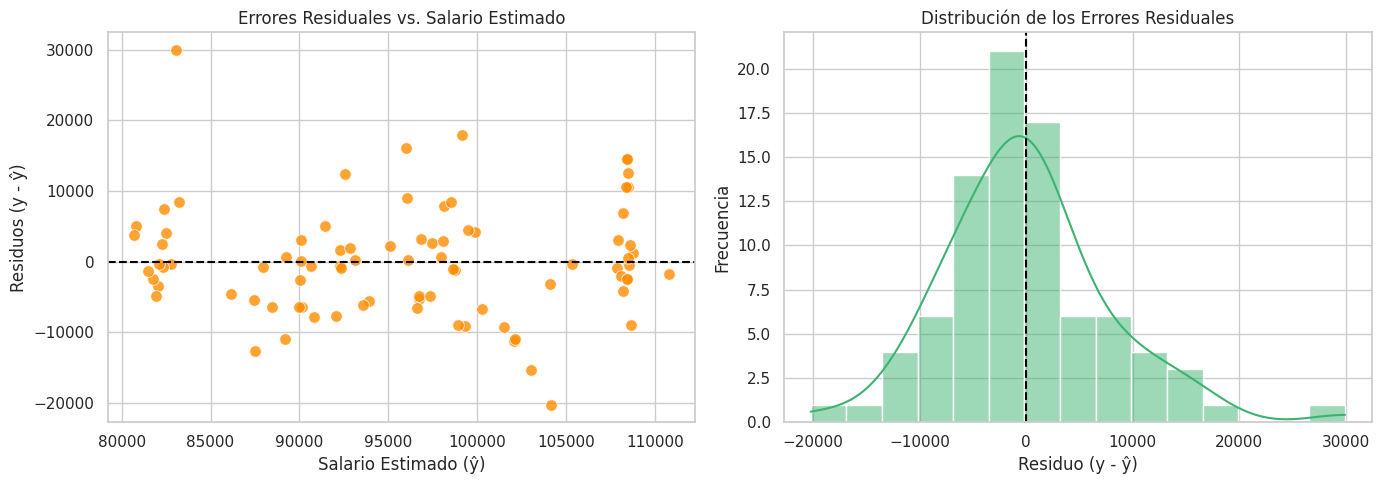

In [41]:

# Calcular las predicciones (salario estimado) y los residuos (errores residuales)
y_pred = modelo.predict(X)
residuos = y - y_pred

# 4.1 Visualización de predicciones (salario estimado) vs valores reales (salario real)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y, y=y_pred, color='steelblue', s=70, alpha=0.8)
min_val = min(y.min(), y_pred.min())
max_val = max(y.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='crimson', linestyle='--', linewidth=2, label='Ajuste ideal (y = ŷ)')
plt.title('Salario Real vs. Salario Estimado (Predicciones)')
plt.xlabel('Salario Real (y)')
plt.ylabel('Salario Estimado (ŷ)')
plt.legend()
plt.show()

# 4.2 Gráfica de los errores residuales (Residuos vs. Predicciones + Distribución)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subgráfica A: Residuos vs Valores Estimados (para evaluar homocedasticidad y linealidad)
sns.scatterplot(x=y_pred, y=residuos, color='darkorange', s=70, alpha=0.8, ax=axes[0])
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Errores Residuales vs. Salario Estimado')
axes[0].set_xlabel('Salario Estimado (ŷ)')
axes[0].set_ylabel('Residuos (y - ŷ)')

# Subgráfica B: Histograma de los residuos (para evaluar normalidad del error)
sns.histplot(residuos, kde=True, bins=15, color='mediumseagreen', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribución de los Errores Residuales')
axes[1].set_xlabel('Residuo (y - ŷ)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### 4.3 Interpretación y Conclusiones del Análisis de Residuos

#### 1. **¿Qué nos indican las gráficas de residuos?**

* **Ajuste general (Predicción vs. Real):** Los puntos siguen de forma clara la línea diagonal roja de ajuste ideal, lo que confirma que el modelo logra capturar la tendencia general de los salarios a partir del costo y la localidad
* **Comportamiento alrededor del cero:** En la gráfica de residuos vs. estimados, la mayoría de los errores se mantienen dispersos de forma equilibrada alrededor de la línea cero, cumpliendo con linealidad y homocedasticidad
* **Forma acampanada (Normalidad):** El histograma de residuos presenta una forma de campana bien definida y centrada en el cero, lo que valida que los errores del modelo se distribuyen de manera normal

#### 2. **Balance del modelo**

* **Fortaleza:** El modelo predice con bastante precisión el salario promedio de la gran mayoría de las instituciones educativas analizadas.

#### **Conclusión del análisis de residuos**

1. **Validez estadística:** El análisis de residuos confirma que el modelo de regresión lineal múltiple es sólido, confiable y cumple con los supuestos  requeridos

# 5. Evalúa el modelo

- 5.1 Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- 5.2 Calcula el R² Score

Discute estos resultados obtenidos.

In [42]:
# Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

# Calcula el R² Score
r2 = r2_score(y, y_pred)

print("Evaluación del Desempeño del Modelo")
print(f"MSE (Error Cuadrático Medio): {mse:,.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:,.4f}")
print(f"R² Score (Coeficiente de Determinación): {r2:.4f} ({r2*100:.2f}%)")

Evaluación del Desempeño del Modelo
MSE (Error Cuadrático Medio): 60,480,269.1466
RMSE (Raíz del Error Cuadrático Medio): 7,776.9061
R² Score (Coeficiente de Determinación): 0.5705 (57.05%)


### 5.3 Interpretación y Conclusiones de la Evaluación del Modelo

#### 1. **¿Qué nos indican las métricas de desempeño?**

* **Error Cuadrático Medio (MSE = 60,480,269):** Es un número elevado en apariencia porque las diferencias entre el sueldo real y el predicho se elevan al cuadrado (quedando en dólares al cuadrado). Esta métrica penaliza los errores grandes y valores atípicos detectados en los residuos
* **Margen de error real en dólares (RMSE = 7,776):** Al sacarle la raíz cuadrada al MSE, obtenemos una interpretación directa en dinero: el modelo se equivoca, en promedio, por 7,777 dólares al estimar el salario anual de una institución
* **Capacidad explicativa (R² = 57.05%):** El modelo explica más de la mitad (57.05%) de las diferencias salariales entre los graduados

#### Conclusión de la evaluación

1. **Aprobación del desempeño:** Para ser un modelo lineal con solo una variable numérica (costo) y una categórica (localidad), alcanzar un 57% de explicación con un error promedio de 7,777 dólares confirma que el modelo es sólido
2. **Cierre de la investigación:** El costo de la carrera sí influye en el salario, pero la localidad es el factor que termina de darle sentido al modelo. Evaluar ambas variables en conjunto permite estimar con certeza el ingreso esperado

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [43]:
import statsmodels.api as sm
from statsmodels.regression.mixed_linear_model import VCSpec

# 6.1 Tabla ANOVA
modelo_ols = sm.OLS.from_formula('salary ~ cost + C(location)', data=df).fit()
tabla_anova = sm.stats.anova_lm(modelo_ols, typ=2)

print("6.1 Tabla ANOVA del modelo de regresion")
print(tabla_anova)
print("\n=== Resumen OLS (Estadístico F y significancia) ===")
print(modelo_ols.summary())

# 6.2 Análisis de Componentes de Varianza
modelo_vc = sm.MixedLM.from_formula(
    'salary ~ cost',
    groups=df['location'],
    data=df
).fit()

print("6.2 Componentes de varianza por localidad")
print(modelo_vc.summary())

6.1 Tabla ANOVA del modelo de regresion
                   sum_sq    df          F        PR(>F)
C(location)  4.071774e+09   3.0  21.121259  3.570975e-10
cost         7.878166e+08   1.0  12.259774  7.600629e-04
Residual     5.140823e+09  80.0        NaN           NaN

=== Resumen OLS (Estadístico F y significancia) ===
                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.96e-14
Time:                        00:56:05   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4          

### 6 Conclusiones del Análisis de Varianza

* **Validez del modelo (F = 26.57, p < 0.001):** La prueba que el modelo es confiable
* **La región marca la diferencia:**
  * **Noreste (p = 0.000):** Garantiza una ventaja salarial estadísticamente significativa de +12,032 dólares
  * **Oeste (p = 0.004):** Presenta una desventaja salarial real de -7,721 dólares
